# ctrlnet 第 13 节演示

本 notebook 与 `scripts/run_demo.py` 内容一致，演示：

- 第 13 节基准/增补方案的精度、相对精度与误差椭圆；
- `r_i`、MDB、外部可靠性；
- 贪心观测增补优化；
- 生成 `outputs/` 下的图件、CSV 与中文汇总 `results.md`。

运行方式（仓库根目录，先安装 `pip install -e ".[test,demo]"`）：

```bash
.venv/bin/python scripts/run_demo.py
```

或执行本 notebook（kernel 名 `ctrlnet-venv`）：

```bash
.venv/bin/python -m jupyter nbconvert \
  --to notebook --execute --inplace \
  --ExecutePreprocessor.kernel_name=ctrlnet-venv notebooks/demo.ipynb
```

In [1]:
from __future__ import annotations

import csv
import os
import sys
from pathlib import Path

# 包已通过 editable 安装导入；ROOT 仅用于定位 outputs/。
try:
    ROOT = Path(__file__).resolve().parents[1]
except NameError:  # notebook 中没有 __file__
    ROOT = Path.cwd()
    if ROOT.name == "notebooks":
        ROOT = ROOT.parent

# matplotlib 缓存放到临时目录，避免只读 HOME 的告警。
os.environ.setdefault(
    "MPLCONFIGDIR", str(Path(os.environ.get("TMPDIR", "/tmp")) / "ctrlnet-mplconfig")
)
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse, Patch

from ctrlnet import (
    K95,
    Angle,
    Distance,
    analyze_precision,
    analyze_reliability,
    format_edge_table,
    format_precision_table,
    format_reliability_table,
    greedy_optimize,
    section13_added,
    section13_base,
    solve,
)

OUTPUTS = ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)
ELLIPSE_SCALE = 1000.0

# 有中文字体时用中文图题，否则退回英文，避免方框乱码。
_available_fonts = {f.name for f in font_manager.fontManager.ttflist}
_CJK_CANDIDATES = [
    "Noto Sans CJK SC",
    "Noto Sans CJK JP",
    "WenQuanYi Zen Hei",
    "Droid Sans Fallback",
]
_CJK_FONT = next((name for name in _CJK_CANDIDATES if name in _available_fonts), None)
if _CJK_FONT:
    plt.rcParams["font.family"] = "sans-serif"
    plt.rcParams["font.sans-serif"] = [_CJK_FONT, "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False


def T(zh: str, en: str) -> str:
    """有中文字体时返回中文，否则返回英文。"""
    return zh if _CJK_FONT else en


SCENARIO_CN = {"base": "基准方案", "added": "增补方案"}
SCENARIO_EN = {"base": "Base scenario", "added": "Added angle scenario"}

In [2]:
# 1. 求解两个方案，并计算标准/95% 精度与可靠性。
scenarios = {"base": section13_base(), "added": section13_added()}
runs: dict[str, dict] = {}
for key, scenario in scenarios.items():
    result = solve(scenario)
    precision = analyze_precision(result, confidence=None)
    precision95 = analyze_precision(result, confidence=0.95)
    reliability = analyze_reliability(result, alpha=0.05, power=0.80)
    runs[key] = {
        "scenario": scenario,
        "result": result,
        "precision": precision,
        "precision95": precision95,
        "reliability": reliability,
    }

for key, run in runs.items():
    scenario = run["scenario"]
    result = run["result"]
    precision = run["precision"]
    reliability = run["reliability"]
    print(f"\n=== {SCENARIO_CN[key]} / {scenario.name} ===")
    print(
        f"观测数={result.n_observations}，参数数={result.n_params}，"
        f"秩={result.rank}，冗余数={result.redundancy}，"
        f"条件数={result.condition_number:.3f}，λ0={reliability.lambda0_value:.3f}"
    )
    print(format_precision_table(precision))
    print()
    print(format_edge_table(precision))
    print()
    print(format_reliability_table(reliability))


=== 基准方案 / 第13节基准方案 ===
观测数=7，参数数=4，秩=4，冗余数=3，条件数=3.648，λ0=7.849
点位精度（单位 mm，椭圆为标准椭圆；长轴方位从北起顺时针）
| 点 | 类型 | σE/mm | σN/mm | mp/mm | 椭圆a/mm | 椭圆b/mm | 长轴方位/° |
|---|---|---:|---:|---:|---:|---:|---:|
| A | 固定 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| B | 固定 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 | 0.000 |
| C * | 待定 | 0.468 | 1.651 | 1.716 | 1.652 | 0.466 | 1.654 |
| D * | 待定 | 0.468 | 1.651 | 1.716 | 1.652 | 0.466 | 178.346 |

边长相对精度
| 边 | 边长/m | σs/mm | 相对精度 |
|---|---:|---:|---:|
| AC * | 100.000 | 1.651 | 1:60565 |
| BC | 141.421 | 1.183 | 1:119522 |
| AD | 141.421 | 1.183 | 1:119522 |
| BD * | 100.000 | 1.651 | 1:60565 |
| CD | 100.000 | 0.643 | 1:155427 |

可靠性（λ0=7.849000，α=0.05，power=0.8）
| 观测 | σ | r_i | MDB | 外部最大影响/mm | 影响点 |
|---|---:|---:|---:|---:|---|
| AC | 2.010 mm | 0.3252 | 9.875 mm | 6.663 | C |
| BC | 2.020 mm | 0.6569 | 6.982 mm | 3.211 | C |
| AD | 2.020 mm | 0.6569 | 6.982 mm | 3.211 | D |
| BD | 2.010 mm | 0.3252 | 9.875 mm | 6.663 | D |
| CD | 2.010 m

In [3]:
# 2. 网图 + 标准（实线）与 95%（虚线）误差椭圆，图中注明放大倍数。
def draw_network(key: str) -> Path:
    run = runs[key]
    scenario = run["scenario"]
    result = run["result"]
    precision95 = run["precision95"]
    network = scenario.network

    title = (
        f"{T('控制网与误差椭圆', 'Control network and error ellipses')} — "
        f"{T(SCENARIO_CN[key], SCENARIO_EN[key])}"
    )
    fig, ax = plt.subplots(figsize=(9.2, 7.0))
    from ctrlnet import plot_network

    plot_network(
        result,
        ax=ax,
        scale=ELLIPSE_SCALE,
        confidence=None,
        show_observation_labels=False,
        title=title,
        figsize=(9.2, 7.0),
    )
    ax.set_xlabel(T("东坐标 E / m", "Easting E / m"))
    ax.set_ylabel(T("北坐标 N / m", "Northing N / m"))
    ax.set_title(
        f"{T('控制网与误差椭圆', 'Control network and error ellipses')} — "
        f"{T(SCENARIO_CN[key], SCENARIO_EN[key])}\n"
        f"{T('椭圆放大', 'ellipses magnified')} {ELLIPSE_SCALE:g}×; "
        f"{T('实线=标准椭圆，虚线=95% 椭圆', 'solid=standard, dashed=95%')}"
    )

    for point in network.points:
        if point.fixed:
            continue
        ellipse95 = precision95.points[point.name].ellipse
        a = ellipse95.a * ELLIPSE_SCALE
        b = ellipse95.b * ELLIPSE_SCALE
        angle = 90.0 - ellipse95.azimuth_deg
        ax.add_patch(
            Ellipse(
                (point.E, point.N),
                width=2.0 * a,
                height=2.0 * b,
                angle=angle,
                facecolor="none",
                edgecolor="tab:red",
                lw=1.0,
                ls="--",
                zorder=4,
            )
        )

    handles, labels = ax.get_legend_handles_labels()
    label_map = {
        "Distance": T("距离", "Distance"),
        "Angle": T("角度", "Angle"),
        "Fixed point": T("固定点", "Fixed point"),
        "Unknown point": T("待定点", "Unknown point"),
    }
    labels = [label_map.get(label, label) for label in labels]
    handles.extend(
        [
            Patch(
                facecolor="tab:blue",
                edgecolor="tab:blue",
                alpha=0.15,
                label=T("标准椭圆（蓝色实线）", "standard ellipse (blue solid)"),
            ),
            Patch(
                facecolor="none",
                edgecolor="tab:red",
                ls="--",
                label=T("95% 椭圆（红色虚线）", "95% ellipse (red dashed)"),
            ),
        ]
    )
    labels.extend(
        [
            T("标准椭圆（蓝色实线）", "standard ellipse (blue solid)"),
            T("95% 椭圆（红色虚线）", "95% ellipse (red dashed)"),
        ]
    )
    # 图例固定在坐标轴右侧外部，绝不遮挡点位或椭圆。
    ax.legend(
        handles,
        labels,
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        fontsize=8,
        borderaxespad=0.0,
        frameon=True,
    )

    xs = [p.E for p in network.points]
    ys = [p.N for p in network.points]
    pad = 14.0
    ax.set_xlim(min(xs) - pad, max(xs) + pad)
    ax.set_ylim(min(ys) - pad, max(ys) + pad)
    fig.tight_layout()
    path = OUTPUTS / f"network_ellipses_{key}.png"
    fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.close(fig)
    return path


network_paths = [draw_network(key) for key in ("base", "added")]
print("\n网图：")
for path in network_paths:
    print(" -", path)


网图：
 - /workspace/ctrlnet-design/outputs/network_ellipses_base.png
 - /workspace/ctrlnet-design/outputs/network_ellipses_added.png


In [4]:
# 3. 方案对比：各点 mp 与各边相对精度分母。
def draw_comparison() -> Path:
    base = runs["base"]["precision"]
    added = runs["added"]["precision"]
    point_names = [name for name in base.point_order if not base.points[name].fixed]
    edge_names = list(base.edge_order)
    if base.edge_order != added.edge_order:
        edge_names = list(dict.fromkeys(base.edge_order + added.edge_order))

    fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2))
    x = np.arange(len(point_names))
    width = 0.36
    base_mp = [base.points[name].mp_mm for name in point_names]
    added_mp = [added.points[name].mp_mm for name in point_names]
    axes[0].bar(x - width / 2, base_mp, width, label=T("基准", "Base"), color="tab:blue")
    axes[0].bar(x + width / 2, added_mp, width, label=T("增补", "Added"), color="tab:orange")
    axes[0].set_xticks(x, point_names)
    axes[0].set_ylabel(T("mp / mm", "mp / mm"))
    axes[0].set_title(T("各点 mp", "Point mp"))
    for container in axes[0].containers:
        axes[0].bar_label(
            container, fmt="%.3f", padding=2, fontsize=7, rotation=90
        )
    axes[0].set_ylim(0.0, max(base_mp + added_mp) * 1.22)

    xe = np.arange(len(edge_names))
    base_den = [base.edges[name].ratio_denominator or 0 for name in edge_names]
    added_den = [added.edges[name].ratio_denominator or 0 for name in edge_names]
    axes[1].bar(xe - width / 2, base_den, width, label=T("基准", "Base"), color="tab:blue")
    axes[1].bar(xe + width / 2, added_den, width, label=T("增补", "Added"), color="tab:orange")
    axes[1].set_xticks(xe, edge_names)
    axes[1].set_ylabel(T("相对精度分母（越大越好）", "1 / σs denominator (higher is better)"))
    axes[1].set_title(T("各边相对精度分母", "Edge relative precision"))
    for container in axes[1].containers:
        axes[1].bar_label(
            container,
            labels=[f"{v / 1000:.1f}k" for v in container.datavalues],
            padding=2,
            fontsize=7,
            rotation=90,
        )
    axes[1].set_ylim(0.0, max(base_den + added_den) * 1.22)

    fig.suptitle(
        T(
            "基准方案 vs 增补方案：精度指标",
            "Base vs added scenario: precision metrics",
        )
    )
    # 共享图例放在两幅子图下方的坐标轴外部，避免遮挡柱体或数值标签。
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.0),
        ncol=2,
        fontsize=8,
        frameon=True,
    )
    fig.tight_layout(rect=(0.0, 0.11, 1.0, 0.94))
    path = OUTPUTS / "scenario_comparison.png"
    fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.close(fig)
    return path


comparison_path = draw_comparison()
print("\n方案对比图：", comparison_path)


方案对比图： /workspace/ctrlnet-design/outputs/scenario_comparison.png


In [5]:
# 4. 可靠性 r_i：两方案每条观测，标出 0.1/0.3/0.5 阈值线。
def short_observation_label(row) -> str:
    if row.kind in ("distance", "gnss"):
        return row.label
    return row.label.replace("∠", "").replace("-", "")


def draw_reliability() -> Path:
    fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.4), sharey=True)
    thresholds = [(0.1, "0.10"), (0.3, "0.30"), (0.5, "0.50")]
    for ax, key in zip(axes, ("base", "added")):
        rel = runs[key]["reliability"]
        labels = [short_observation_label(row) for row in rel.records]
        values = [row.r_i for row in rel.records]
        bar_colors = [
            "tab:red" if value < 0.1 else ("tab:orange" if value < 0.3 else "tab:blue")
            for value in values
        ]
        x = np.arange(len(labels))
        ax.bar(x, values, color=bar_colors, width=0.68)
        ax.set_xticks(x, labels, rotation=25, ha="right")
        ax.set_ylim(0.0, 1.08)
        ax.set_ylabel(T("多余观测分量 r_i", "Redundancy number r_i"))
        ax.set_title(
            f"{T(SCENARIO_CN[key], SCENARIO_EN[key])}  "
            f"(Σr_i={rel.sum_r:.3f}, {T('冗余数', 'redundancy')}={rel.expected_redundancy})"
        )
        for value, xi in zip(values, x):
            ax.text(
                xi,
                value + 0.015,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=7,
                rotation=90,
            )
        for threshold, label in thresholds:
            ax.axhline(threshold, color="0.35", lw=0.9, ls="--", zorder=0)
            # 阈值文字放在最右一条柱子上方的空白处，避免压住柱体。
            ax.text(
                0.985,
                threshold + 0.012,
                label,
                transform=ax.get_yaxis_transform(),
                fontsize=7,
                color="0.30",
                ha="right",
                va="bottom",
                zorder=8,
                bbox=dict(
                    boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85
                ),
            )
    handles = [
        Line2D([0], [0], color="0.35", lw=0.9, ls="--", label=T("常用阈值", "common thresholds")),
        Patch(color="tab:red", label=T("r_i < 0.1", "r_i < 0.1")),
        Patch(color="tab:orange", label=T("0.1 ≤ r_i < 0.3", "0.1 ≤ r_i < 0.3")),
        Patch(color="tab:blue", label=T("r_i ≥ 0.3", "r_i ≥ 0.3")),
    ]
    # 图例放在两幅子图下方外部，避免遮挡接近 1.0 的柱体和数值标签。
    fig.legend(
        handles=handles,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.0),
        ncol=4,
        fontsize=7.5,
        frameon=True,
    )
    fig.suptitle(T("两方案多余观测分量 r_i", "Redundancy numbers r_i for both scenarios"))
    fig.tight_layout(rect=(0.0, 0.15, 1.0, 0.94))
    path = OUTPUTS / "reliability_ri.png"
    fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.close(fig)
    return path


reliability_path = draw_reliability()
print("\n可靠性图：", reliability_path)


可靠性图： /workspace/ctrlnet-design/outputs/reliability_ri.png


In [6]:
# 5. 贪心优化：候选角/距离，目标为最小化最大 mp。
candidates = [
    Angle("A", "C", "D"),
    Angle("B", "D", "C"),
    Angle("D", "C", "A"),
    Angle("C", "B", "D"),
    Angle("D", "A", "C"),
    Distance("A", "B"),  # 两端均为固定点，无信息增益
]
optimization = greedy_optimize(
    runs["base"]["scenario"], candidates, objective="max_mp"
)
print(
    f"\n优化：初始 max mp={optimization.initial_metrics.objective * 1000:.3f} mm，"
    f"最终={optimization.final_metrics.objective * 1000:.3f} mm，"
    f"步数={len(optimization.steps)}，成本={optimization.spent:g}"
)
for step in optimization.steps:
    print(
        f"  第 {step.step} 步：+{step.added_label}，"
        f"目标={step.objective * 1000:.3f} mm，"
        f"收益={step.gain * 1000:.3f} mm"
    )


优化：初始 max mp=1.716 mm，最终=0.858 mm，步数=5，成本=5
  第 1 步：+∠A-C-D，目标=1.310 mm，收益=0.406 mm
  第 2 步：+∠D-A-C，目标=1.039 mm，收益=0.271 mm
  第 3 步：+∠B-D-C，目标=0.952 mm，收益=0.088 mm
  第 4 步：+∠C-B-D，目标=0.863 mm，收益=0.089 mm
  第 5 步：+∠D-C-A，目标=0.858 mm，收益=0.005 mm


In [7]:
# 6. 优化过程图。
def draw_optimizer() -> Path:
    x = [0] + [step.step for step in optimization.steps]
    y = [optimization.initial_metrics.objective * 1000.0] + [
        step.objective * 1000.0 for step in optimization.steps
    ]
    annotations = [T("初始", "initial")] + [step.added_label for step in optimization.steps]
    fig, ax = plt.subplots(figsize=(9.8, 5.2))
    ax.step(x, y, where="post", color="tab:blue", lw=1.8)
    ax.scatter(x, y, color="tab:blue", s=45, zorder=3)
    # 初始点标在点的左上方，其余点标在点下方，并用细引导线连接，避免压住折线。
    for index, (xi, yi, text) in enumerate(zip(x, y, annotations)):
        if index == 0:
            offset = (8, 12)
            ha, va = "left", "bottom"
        else:
            offset = (0, -22)
            ha, va = "center", "top"
        ax.annotate(
            text,
            (xi, yi),
            textcoords="offset points",
            xytext=offset,
            fontsize=7.5,
            ha=ha,
            va=va,
            zorder=6,
            bbox=dict(
                boxstyle="round,pad=0.2", fc="white", ec="0.75", alpha=0.95
            ),
            arrowprops=dict(
                arrowstyle="-", color="0.55", lw=0.6, shrinkA=0, shrinkB=2
            ),
        )
    ax.set_xlabel(T("贪心步（0=初始）", "Greedy step (0 = initial)"))
    ax.set_ylabel(T("最大 mp / mm", "max mp / mm"))
    ax.set_title(
        T(
            "贪心观测增补：每步最大点位中误差",
            "Greedy observation augmentation: max mp per step",
        )
    )
    span = max(y) - min(y)
    headroom = max(span * 0.28, 0.08)
    ax.set_ylim(min(y) - headroom, max(y) + headroom)
    ax.set_xlim(-0.35, len(x) - 0.35)
    ax.grid(True, color="0.9")
    fig.tight_layout()
    path = OUTPUTS / "optimizer_steps.png"
    fig.savefig(path, dpi=170, bbox_inches="tight")
    plt.close(fig)
    return path


optimizer_path = draw_optimizer()
print("\n优化过程图：", optimizer_path)


优化过程图： /workspace/ctrlnet-design/outputs/optimizer_steps.png


In [8]:
# 7. 导出 CSV 表。
def write_csv(filename: str, header: list[str], rows: list[list[object]]) -> Path:
    path = OUTPUTS / filename
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.writer(handle)
        writer.writerow(header)
        writer.writerows(rows)
    return path


point_rows: list[list[object]] = []
edge_rows: list[list[object]] = []
reliability_rows: list[list[object]] = []
for key, run in runs.items():
    precision = run["precision"]
    precision95 = run["precision95"]
    reliability = run["reliability"]
    for name in precision.point_order:
        point = precision.points[name]
        point95 = precision95.points[name]
        point_rows.append(
            [
                key,
                name,
                point.role,
                f"{point.sigma_E_mm:.6f}",
                f"{point.sigma_N_mm:.6f}",
                f"{point.mp_mm:.6f}",
                f"{point.ellipse.standard_major * 1000.0:.6f}",
                f"{point.ellipse.standard_minor * 1000.0:.6f}",
                f"{point.ellipse.azimuth_deg:.6f}",
                f"{point95.ellipse.a * 1000.0:.6f}",
                f"{point95.ellipse.b * 1000.0:.6f}",
            ]
        )
    for label in precision.edge_order:
        edge = precision.edges[label]
        edge_rows.append(
            [
                key,
                label,
                f"{edge.length:.6f}",
                f"{edge.sigma_s_mm:.6f}",
                edge.ratio_denominator if edge.ratio_denominator is not None else "",
                edge.ratio_text,
            ]
        )
    for row in reliability.records:
        if row.kind in ("angle", "direction"):
            sigma_value = row.sigma * (180.0 * 3600.0 / np.pi)
            sigma_unit = "arcsec"
            mdb_value = row.mdb_display
        else:
            sigma_value = row.sigma * 1000.0
            sigma_unit = "mm"
            mdb_value = row.mdb_display
        reliability_rows.append(
            [
                key,
                row.label,
                row.kind,
                f"{sigma_value:.6f}",
                sigma_unit,
                f"{row.r_i:.6f}",
                f"{mdb_value:.6f}" if np.isfinite(mdb_value) else "inf",
                row.mdb_unit,
                f"{row.external_max_mm:.6f}",
                f"{row.external_max_norm_mm:.6f}",
                row.external_point or "",
                1 if row.undetectable else 0,
            ]
        )

optimizer_rows: list[list[object]] = []
optimizer_rows.append(
    [
        0,
        "(initial)",
        0.0,
        0.0,
        f"{optimization.initial_metrics.objective * 1000.0:.6f}",
        "0.000000",
        f"{optimization.initial_metrics.max_mp * 1000.0:.6f}",
        f"{optimization.initial_metrics.worst_relative:.9f}",
        "",
    ]
)
for step in optimization.steps:
    optimizer_rows.append(
        [
            step.step,
            step.added_label,
            f"{step.cost:g}",
            f"{step.total_cost:g}",
            f"{step.objective * 1000.0:.6f}",
            f"{step.gain * 1000.0:.6f}",
            f"{step.max_mp * 1000.0:.6f}",
            f"{step.worst_relative:.9f}",
            ";".join(step.selected_labels),
        ]
    )

point_csv = write_csv(
    "points.csv",
    [
        "scenario",
        "point",
        "role",
        "sigma_E_mm",
        "sigma_N_mm",
        "mp_mm",
        "ellipse_a_mm",
        "ellipse_b_mm",
        "ellipse_azimuth_deg",
        "ellipse95_a_mm",
        "ellipse95_b_mm",
    ],
    point_rows,
)
edge_csv = write_csv(
    "edges.csv",
    ["scenario", "edge", "length_m", "sigma_s_mm", "relative_denominator", "relative_text"],
    edge_rows,
)
reliability_csv = write_csv(
    "reliability.csv",
    [
        "scenario",
        "observation",
        "kind",
        "sigma",
        "sigma_unit",
        "r_i",
        "mdb",
        "mdb_unit",
        "external_max_component_mm",
        "external_max_norm_mm",
        "external_point",
        "undetectable",
    ],
    reliability_rows,
)
optimizer_csv = write_csv(
    "optimizer.csv",
    [
        "step",
        "added",
        "cost",
        "total_cost",
        "objective_mp_mm",
        "gain_mm",
        "max_mp_mm",
        "worst_relative",
        "selected_labels",
    ],
    optimizer_rows,
)
print("\nCSV：")
for path in (point_csv, edge_csv, reliability_csv, optimizer_csv):
    print(" -", path)


CSV：
 - /workspace/ctrlnet-design/outputs/points.csv
 - /workspace/ctrlnet-design/outputs/edges.csv
 - /workspace/ctrlnet-design/outputs/reliability.csv
 - /workspace/ctrlnet-design/outputs/optimizer.csv


In [9]:
# 8. 生成中文汇总 results.md。
lines = [
    "# ctrlnet 演示结果（第 13 节）",
    "",
    "由 `scripts/run_demo.py` 生成；数值为设计态/先验精度。",
    "",
    f"- 标准椭圆系数 1；95% 椭圆系数 k = sqrt(-2 ln 0.05) = {K95:.6f}。",
    "- 网图中椭圆放大 1000 倍；实线为标准椭圆，虚线为 95% 椭圆。",
    "- 外部可靠性取 MDB 引起的最大单个坐标分量绝对值（mm）。",
    "- λ0 = 7.849（α=0.05，power=0.80）。",
    "",
    "## 1. 点位精度",
    "",
    "| 方案 | 点 | σE/mm | σN/mm | mp/mm | 标准 a/mm | 标准 b/mm | 95% a/mm | 95% b/mm |",
    "|---|---|---:|---:|---:|---:|---:|---:|---:|",
]
for key, run in runs.items():
    precision = run["precision"]
    precision95 = run["precision95"]
    for name in precision.point_order:
        point = precision.points[name]
        if point.fixed:
            continue
        point95 = precision95.points[name]
        lines.append(
            f"| {SCENARIO_CN[key]} | {name} | {point.sigma_E_mm:.3f} | "
            f"{point.sigma_N_mm:.3f} | {point.mp_mm:.3f} | "
            f"{point.ellipse.standard_major * 1000.0:.3f} | "
            f"{point.ellipse.standard_minor * 1000.0:.3f} | "
            f"{point95.ellipse.a * 1000.0:.3f} | {point95.ellipse.b * 1000.0:.3f} |"
        )

lines += [
    "",
    "## 2. 边长相对精度",
    "",
    "| 方案 | 边 | 边长/m | σs/mm | 相对精度 |",
    "|---|---|---:|---:|---:|",
]
for key, run in runs.items():
    precision = run["precision"]
    for label in precision.edge_order:
        edge = precision.edges[label]
        lines.append(
            f"| {SCENARIO_CN[key]} | {label} | {edge.length:.3f} | "
            f"{edge.sigma_s_mm:.3f} | {edge.ratio_text} |"
        )

lines += [
    "",
    "## 3. 可靠性",
    "",
    "| 方案 | 观测 | 类型 | σ | r_i | MDB | 外部最大分量/mm | 影响点 |",
    "|---|---|---|---:|---:|---:|---:|---|",
]
for key, run in runs.items():
    reliability = run["reliability"]
    for row in reliability.records:
        if row.kind in ("angle", "direction"):
            sigma = f"{row.sigma * (180.0 * 3600.0 / np.pi):.3f}″"
            mdb = f"{row.mdb_display:.3f}″"
        else:
            sigma = f"{row.sigma * 1000.0:.3f} mm"
            mdb = f"{row.mdb_display:.3f} mm"
        lines.append(
            f"| {SCENARIO_CN[key]} | {row.label} | {row.kind} | {sigma} | "
            f"{row.r_i:.4f} | {mdb} | {row.external_max_mm:.3f} | "
            f"{row.external_point or '—'} |"
        )
    lines.append(
        f"| {SCENARIO_CN[key]} | 合计 | — | — | "
        f"{reliability.sum_r:.6f}（冗余数 {reliability.expected_redundancy}） | — | — | — |"
    )

lines += [
    "",
    "## 4. 贪心优化",
    "",
    f"目标：最小化最大 mp；初始 {optimization.initial_metrics.objective * 1000.0:.3f} mm，"
    f"最终 {optimization.final_metrics.objective * 1000.0:.3f} mm。",
    "",
    "| 步 | 新增观测 | 成本 | 累计成本 | 目标 mp/mm | 收益/mm |",
    "|---:|---|---:|---:|---:|---:|",
]
lines.append(
    f"| 0 | （初始） | 0 | 0 | "
    f"{optimization.initial_metrics.objective * 1000.0:.3f} | — |"
)
for step in optimization.steps:
    lines.append(
        f"| {step.step} | {step.added_label} | {step.cost:g} | {step.total_cost:g} | "
        f"{step.objective * 1000.0:.3f} | {step.gain * 1000.0:.3f} |"
    )

lines += [
    "",
    "## 5. 文件",
    "",
    "- `network_ellipses_base.png`、`network_ellipses_added.png`：网图 + 标准/95% 椭圆；",
    "- `scenario_comparison.png`：点位 mp 与边相对精度分母；",
    "- `reliability_ri.png`：两方案 r_i 与 0.1/0.3/0.5 阈值线；",
    "- `optimizer_steps.png`：贪心每步目标值；",
    "- `points.csv`、`edges.csv`、`reliability.csv`、`optimizer.csv`：明细表。",
    "",
]
results_path = OUTPUTS / "results.md"
results_path.write_text("\n".join(lines), encoding="utf-8")
print("\n汇总报告：", results_path)


汇总报告： /workspace/ctrlnet-design/outputs/results.md


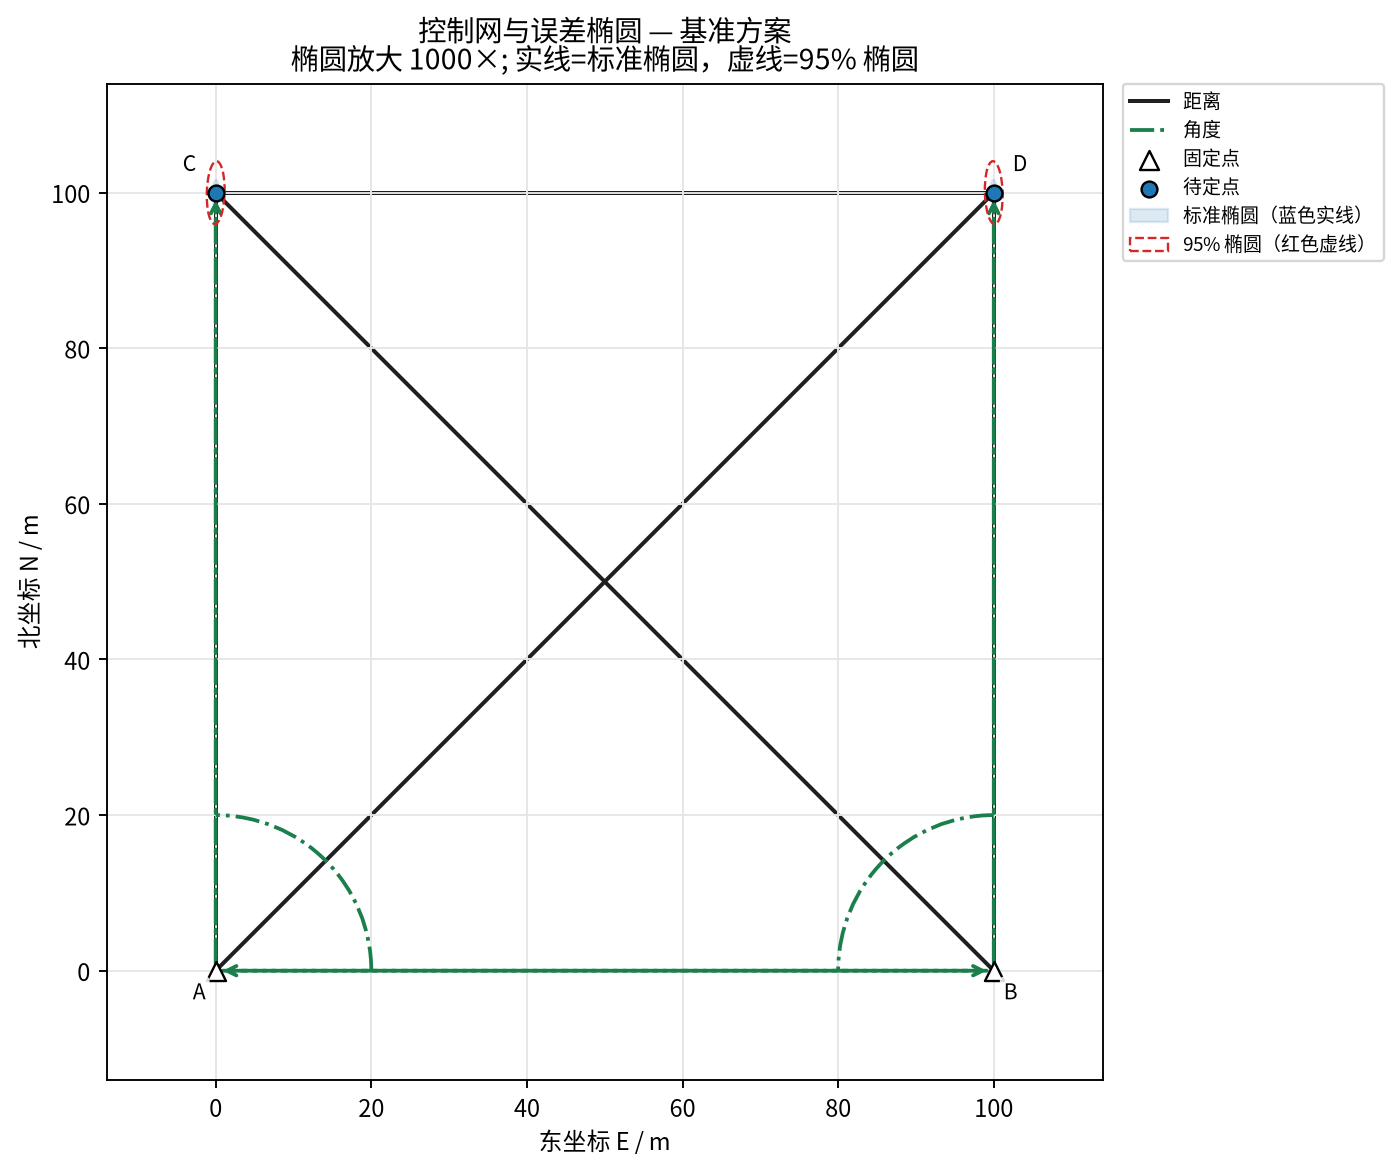

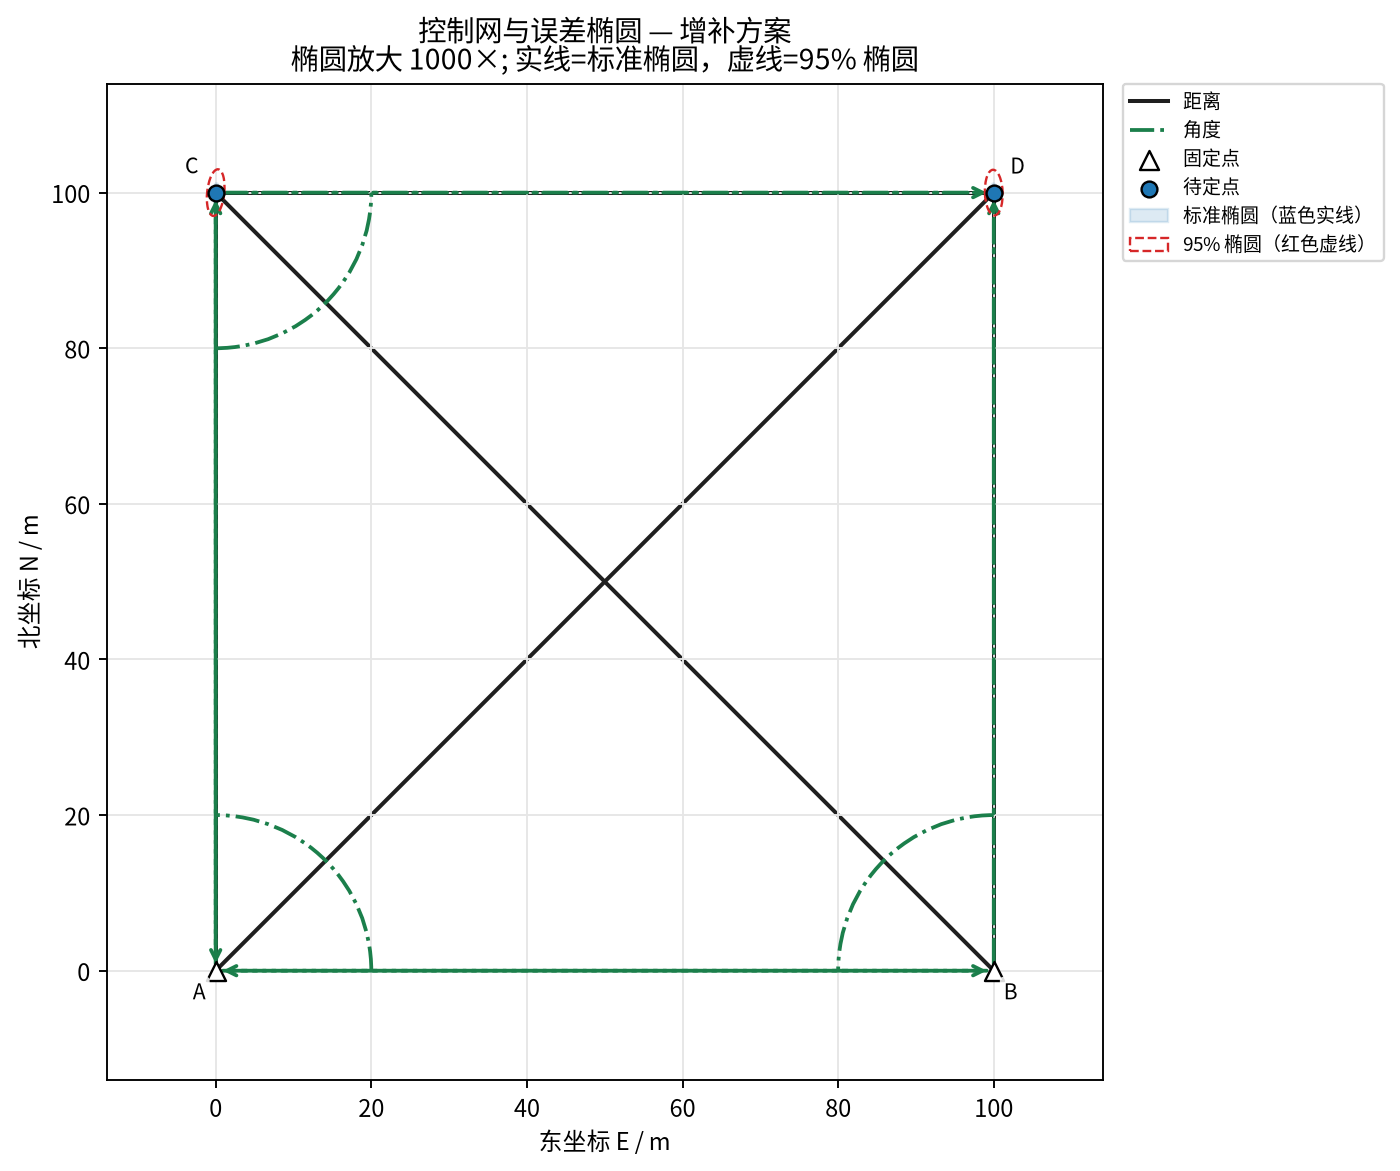

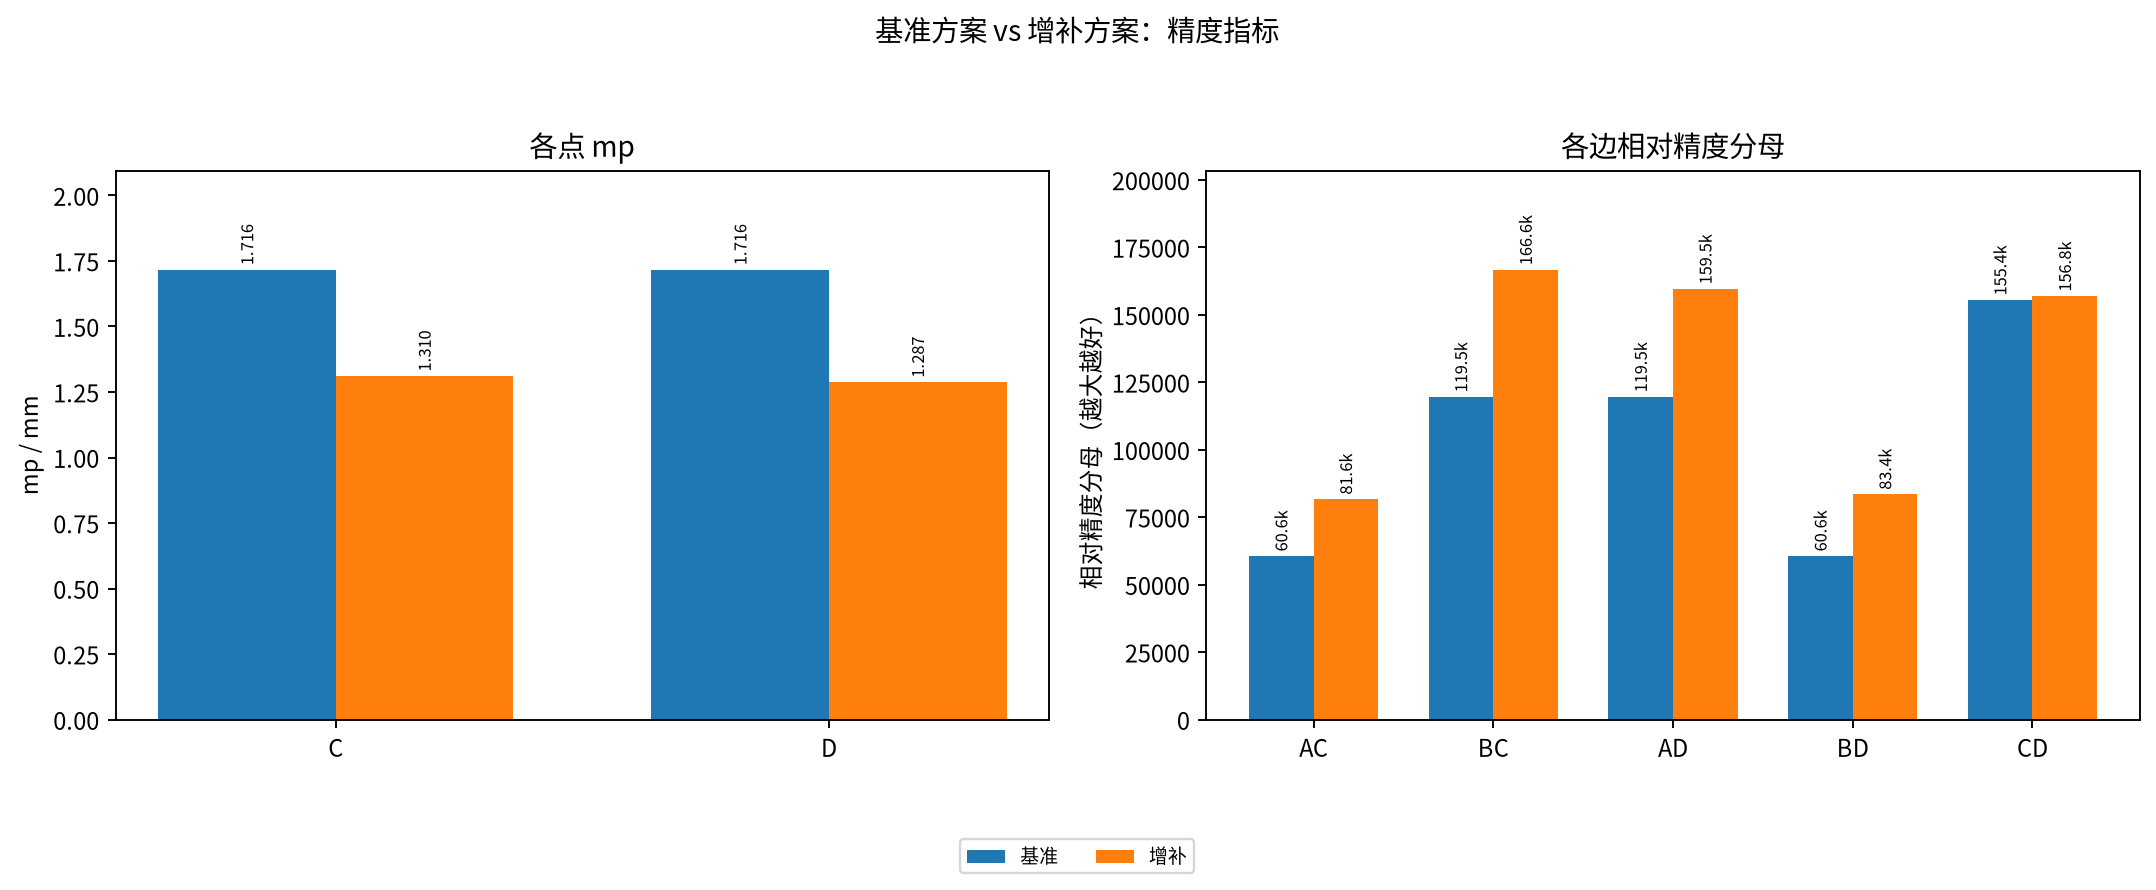

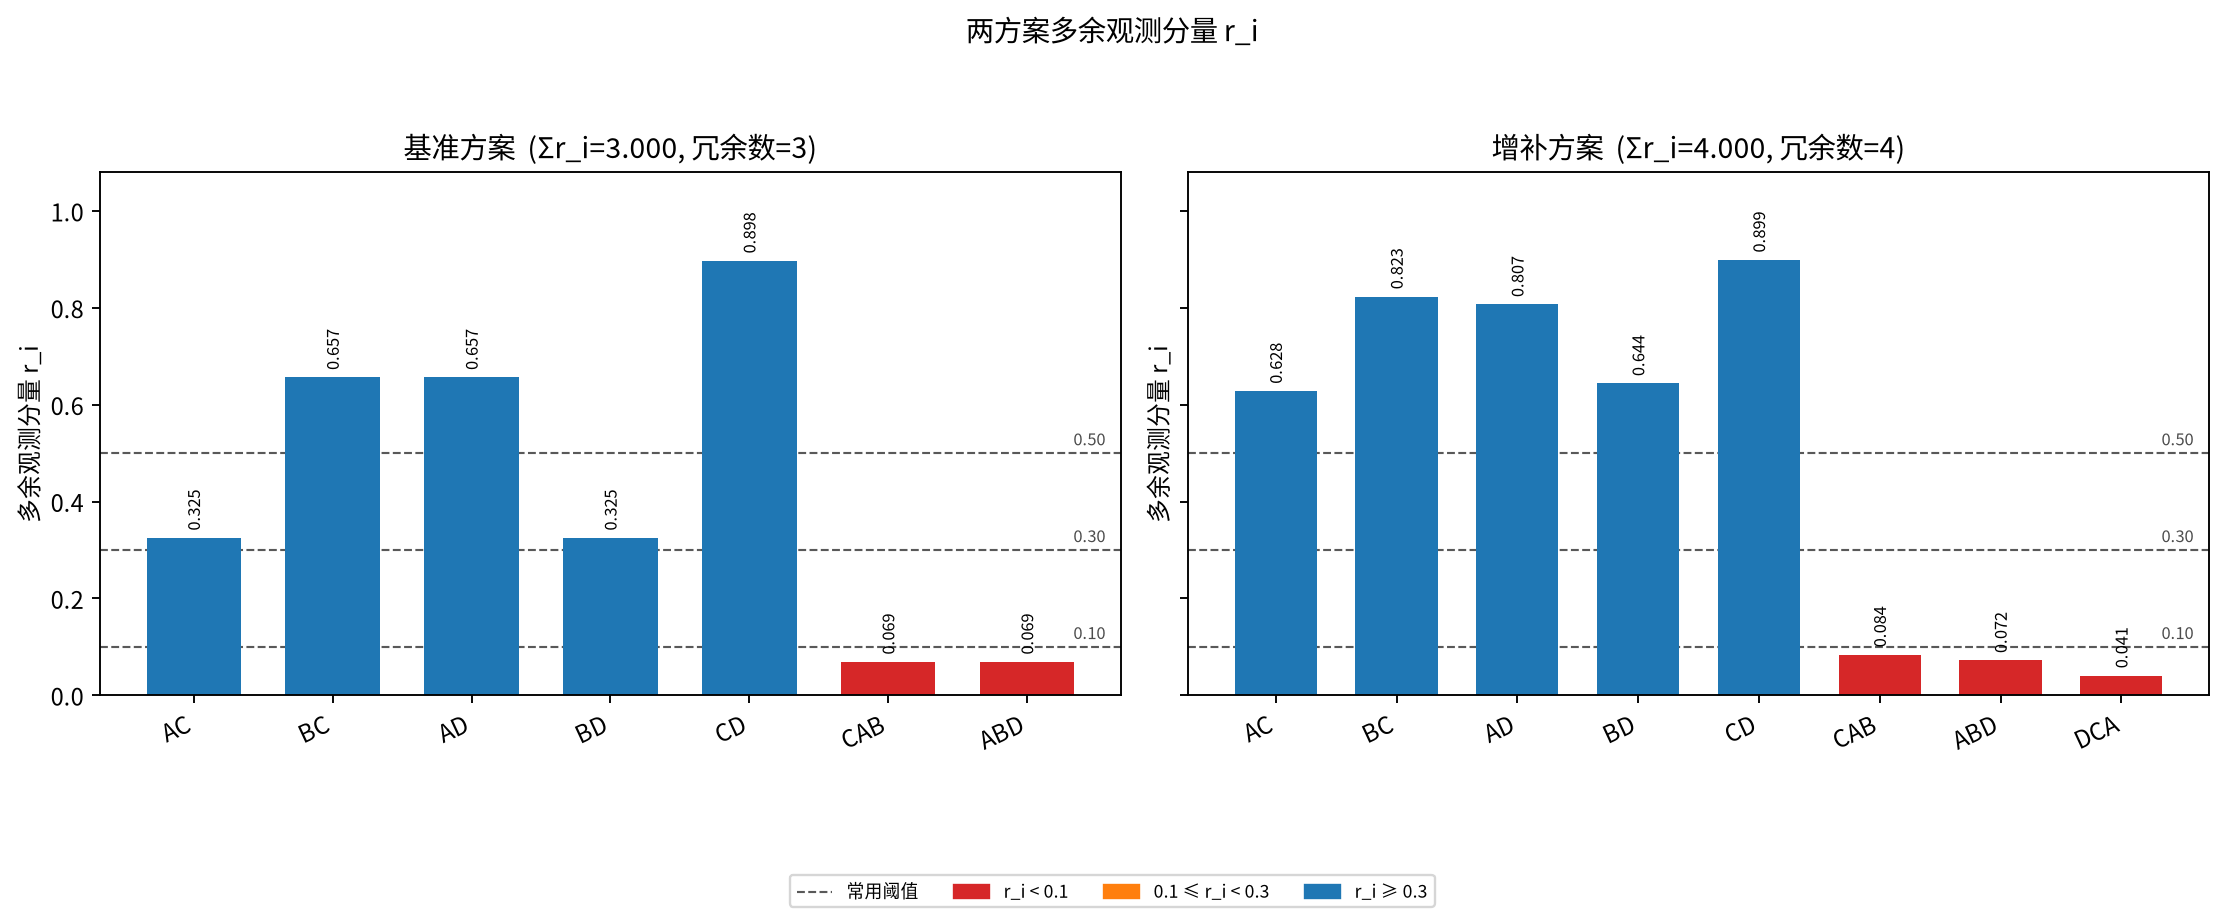

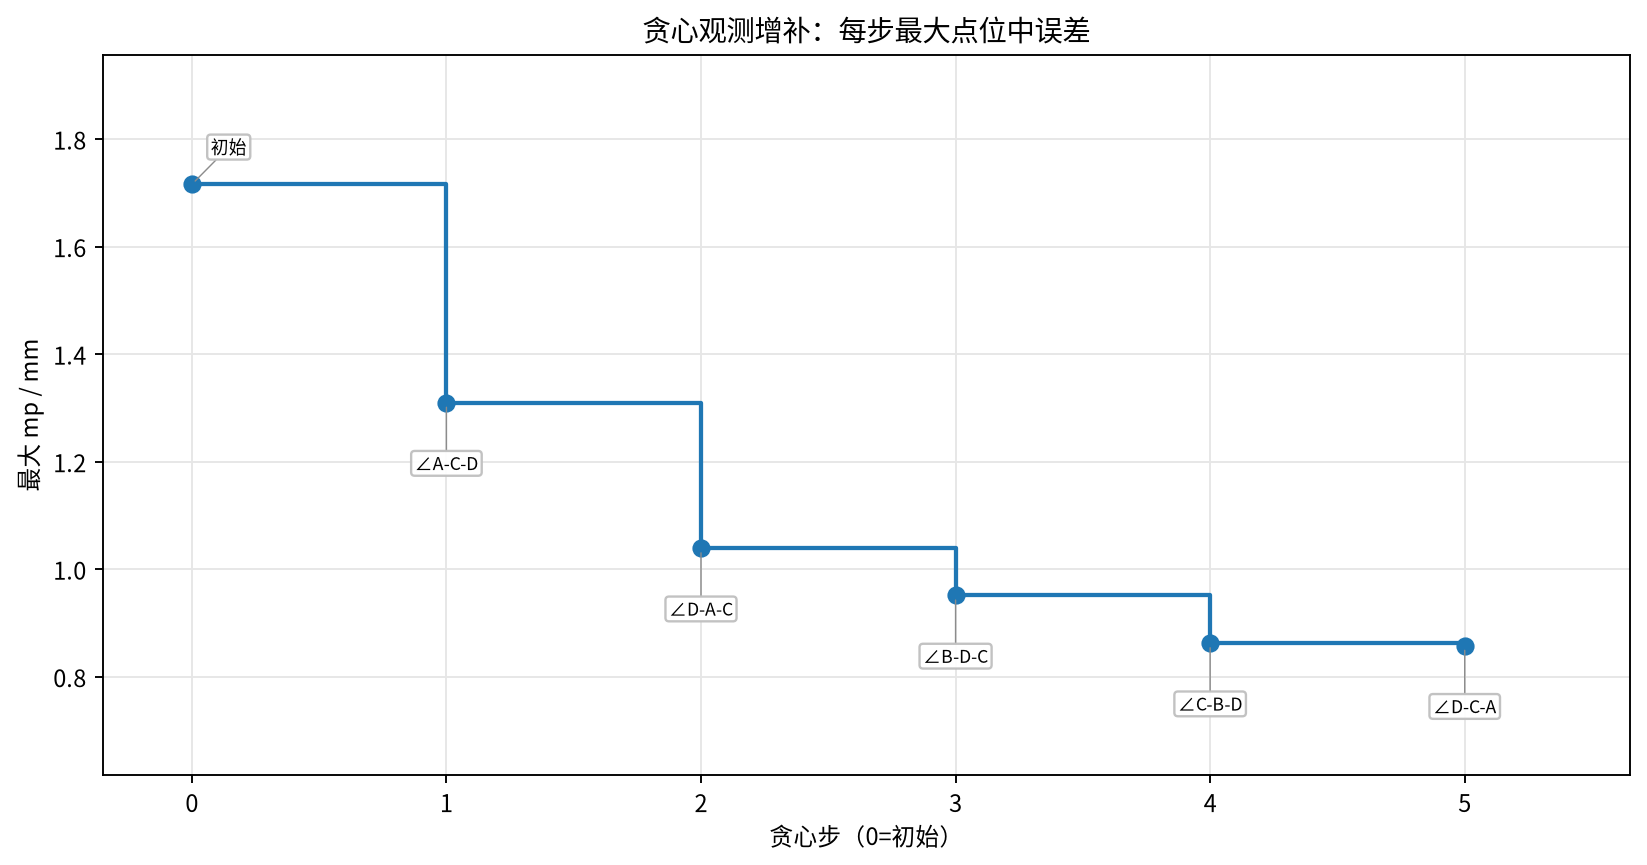

In [10]:
# 9. notebook 中内联显示生成的图（脚本运行时不产生额外文件）。
if "ipykernel" in sys.modules:
    try:
        from IPython.display import Image, display

        for path in (
            network_paths[0],
            network_paths[1],
            comparison_path,
            reliability_path,
            optimizer_path,
        ):
            display(Image(filename=str(path)))
    except Exception:
        pass